In [1]:
import sys
import os
import glob
import importlib

import tqdm

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import corner

%matplotlib inline

In [3]:
import multiprocessing

print(multiprocessing.cpu_count())
# os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={multiprocessing.cpu_count()}"
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count=4"

64


In [4]:
import jax
jax.config.update('jax_enable_x64', True)

import jax.random
import jax.numpy as jnp

importlib.reload(jax)
importlib.reload(jax.random)
importlib.reload(jnp)

<module 'jax.numpy' from '/DATA/CARINA_4/mit227/conda_envs/envs/carina_env/lib/python3.13/site-packages/jax/numpy/__init__.py'>

In [5]:
import discovery as ds
import discovery.models.nanograv as ds_nanograv
import discovery.samplers.numpyro as ds_numpyro
importlib.reload(ds)
importlib.reload(ds_nanograv)
importlib.reload(ds_numpyro)
importlib.reload(ds.pulsar)
importlib.reload(ds.likelihood)
importlib.reload(ds.signals)
importlib.reload(ds.matrix)
importlib.reload(ds.prior)

/pulsar/psr/software/stable/src/util/miniforge/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'discovery.prior' from '/h/mit227/discovery-ppa/src/discovery/prior.py'>

In [6]:
from discovery import prior
from discovery.params import Params, make_layout

import numpyro
from numpyro import infer, distributions as dist

In [7]:
psr = ds.Pulsar.read_feather('/DATA/CARINA_4/mit227/subband_PA_data/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
print(psr)

<Pulsar J0835-4510: 906 res, 0 pars>


In [8]:
with np.printoptions(threshold=sys.maxsize):
    print(np.degrees(psr.residuals))
    print(np.degrees(psr.toaerrs))

[-8.84501217e-01 -8.51900934e-01 -7.25393185e-01 -4.18091032e-01
 -6.80593299e-01 -1.17847759e+00 -1.45053504e+00 -2.83311705e+00
  5.03883640e-01  9.13594900e-01  4.85341692e-01  6.44205520e-01
  3.96612746e-01  1.63502615e-01  2.38447004e-01 -7.17714011e-01
 -9.87151563e-01 -2.77865411e-01  1.79847445e-01  2.10545827e-01
 -2.58670117e-01 -6.07142045e-01 -5.26553382e-01 -1.44439753e+00
  3.27537433e-01 -3.26801395e-01 -3.66910734e-01 -3.57930738e-01
 -7.71916295e-01 -1.18104660e+00 -1.25525479e+00 -2.70111515e+00
  1.43413690e+00  6.53291413e-01  2.98026853e-01  3.41756721e-01
 -2.42235349e-01 -3.68957534e-01 -2.44687181e+00 -2.94368553e+00
  2.38384784e+00  2.17422224e+00  1.37092913e+00  1.16360412e+00
  7.08405332e-01  5.59851825e-01  3.76466719e-01 -7.25360167e-01
  3.39901475e+00  2.62513314e+00  1.34735814e+00  8.95747660e-01
  2.29533489e-01 -1.41473707e-01 -4.85373234e-01 -1.82544807e+00
  3.62822095e+00  1.27421432e+00  3.91969450e-01 -5.41106724e-01
 -1.02098661e+00 -2.58594

In [9]:
with np.printoptions(threshold=sys.maxsize):
    print(psr.freqs)
    print(psr.subbands)

[ 815.817 1059.34  1417.67  1779.336 2106.865 2765.164 3258.797 3807.423
  829.671 1058.386 1417.825 1778.925 2106.756 2764.758 3258.055 3807.12
  824.012 1061.902 1417.644 1779.596 2106.982 2764.355 3258.277 3807.064
  809.202 1057.916 1412.965 1779.336 2106.407 2764.772 3258.315 3807.778
  808.833 1058.122 1418.11  1778.419 2106.756 2764.772 3257.976 3808.261
  827.337 1054.726 1417.155 1781.193 2107.275 2764.514 3258.76  3805.338
  824.777 1049.397 1417.5   1777.368 2107.275 2764.758 3259.076 3808.606
 1059.151 1777.937 2107.275 2764.758 3258.742 3808.734  815.648 1060.508
 1409.157 1778.856 2107.275 2769.102 3258.315 3804.768  813.214 1063.882
 1416.556 1778.467 2107.275 2764.755 3258.547 3806.957  825.166 1064.251
 1415.293 1779.157 2107.275 2764.755 3258.434 3809.418  826.363 1064.251
 1416.417 1779.336 2107.275 2764.755 3258.778 3807.778  807.234 1061.373
 1416.259 1779.837 2107.275 2767.87  3258.357 3807.737 1778.861 2107.275
 2764.755 3258.547 3807.93  1778.67  2107.275 2764.7

In [10]:
obs_PA_dict = {}
for obs in psr.obsnames:
    mask = psr.obsnames == obs
    obs_sbs = psr.subbands[mask]
    obs_PAs = psr.residuals[mask]

    PA_list_for_dict = []
    i_in_orig = 0
    for sb in range(1,8+1):
        if sb in obs_sbs:
            PA_list_for_dict.append(obs_PAs[i_in_orig])
            i_in_orig += 1
        else:
            PA_list_for_dict.append(np.nan)

    obs_PA_dict[obs] = PA_list_for_dict

pd.set_option('display.max_rows', None)
df = pd.DataFrame(obs_PA_dict, index=range(1,8+1)).T
df

,1,2,3,4,5,6,7,8
uwl_181217_121653_b4,-0.015437,-0.014868,-0.012660,-0.007297,-0.011879,-0.020568,-0.025317,-0.049447
uwl_190116_101953_b4,0.008794,0.015945,0.008471,0.011244,0.006922,0.002854,0.004162,-0.012526
uwl_190217_075543_b4,-0.017229,-0.004850,0.003139,0.003675,-0.004515,-0.010597,-0.009190,-0.025209
uwl_190315_060644_b4,0.005717,-0.005704,-0.006404,-0.006247,-0.013472,-0.020613,-0.021908,-0.047143
uwl_190505_025712_b4,0.025030,0.011402,0.005202,0.005965,-0.004228,-0.006440,-0.042706,-0.051377
uwl_190612_004613_b4,0.041606,0.037947,0.023927,0.020309,0.012364,0.009771,0.006571,-0.012660
uwl_190705_225423_b4,0.059324,0.045817,0.023516,0.015634,0.004006,-0.002469,-0.008471,-0.031860
uwl_190727_212113_b4,NaN,0.063324,NaN,0.022239,0.006841,-0.009444,-0.017820,-0.045133
uwl_190823_194513_b4,0.112710,0.063614,0.036396,0.025344,0.013953,0.002235,-0.000599,-0.021455
uwl_190917_175854_b4,0.121362,0.068534,0.038994,0.029855,0.016492,0.005408,0.002602,-0.016616


In [11]:
print(psr.backend_flags)

['P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_

[]

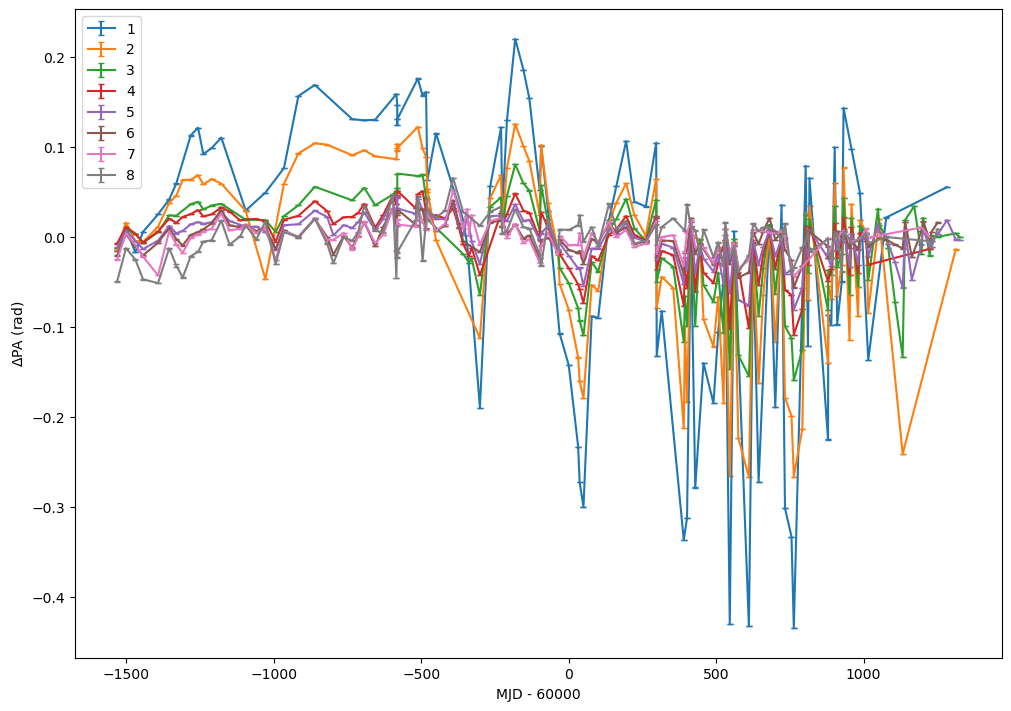

In [11]:
from astropy.time import Time

fig, ax = plt.subplots(1, 1, figsize=(10, 7), layout='constrained')

for sb in range(1,8+1):
    mask = psr.subbands == sb
    t = Time(psr.toas[mask], format='unix', scale='utc')
    ax.errorbar(t.mjd-60000, 
                # np.degrees(
                    psr.residuals[mask],
                    # ), 
                # np.degrees(
                    psr.toaerrs[mask],
                    # ), 
                capsize=2.5, label=sb)

ax.set_xlabel('MJD - 60000')
ax.set_ylabel('$\\Delta$PA (rad)')
ax.legend()
plt.plot()

In [12]:
print(str(b'J0835-4510'))

b'J0835-4510'


In [13]:
type(psr.residuals)

numpy.ndarray

#### Measurement noise only

In [12]:
m = ds.PulsarLikelihood([psr.residuals,#np.nan_to_num(psr.residuals, nan=0.0),
                         ds.makenoise_measurement(psr)])

In [13]:
m.logL.params

['J0835-4510_P574_UWL_efac', 'J0835-4510_P574_UWL_log10_t2equad']

In [18]:
p0 = ds.sample_uniform(m.logL.params)
print(p0)
print(m.logL(p0))

{'J0835-4510_P574_UWL_efac': 1.3668525231009214, 'J0835-4510_P574_UWL_log10_t2equad': -2.339022997653129}
-47063.12576839414


#### Add ECORR noise (GP), free params

In [24]:
m_ecorr = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr),
                         ds.makegp_ecorr(psr)])
print(m_ecorr.logL.params)

AttributeError: 'Pulsar' object has no attribute 'pos'

In [23]:
p0 = ds.sample_uniform(m_ecorr.logL.params)
print(p0)
print(f'w/  ECORR: {m_ecorr.logL(p0)}')
print(f'w/o ECORR: {m_ecorr.logL(p0)}')

{'J0835-4510_efac': 6.889533182146153, 'J0835-4510_log10_ecorr': -1.4410843659559762, 'J0835-4510_log10_t2equad': -3.192201092829763}
w/  ECORR: -43843.31754084448
w/o ECORR: -43843.31754084448


#### Add RM noise

In [19]:
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
print(m_RM.logL.params)

['J0835-4510_efac', 'J0835-4510_log10_ecorr', 'J0835-4510_log10_t2equad', 'J0835-4510_rmgp_gamma', 'J0835-4510_rmgp_log10_A']


In [20]:
p0 = ds.sample_uniform(m_RM.logL.params)
print(p0)
print(f'Noise:          {m.logL(p0):e}')
print(f'Noise+ECORR:    {m_ecorr.logL(p0):e}')
print(f'Noise+ECORR+RM: {m_RM.logL(p0):e}')

{'J0835-4510_efac': 6.044119372918456, 'J0835-4510_log10_ecorr': -2.336938311235409, 'J0835-4510_log10_t2equad': -2.191895086547349, 'J0835-4510_rmgp_gamma': 0.8212855802371231, 'J0835-4510_rmgp_log10_A': -7.506690413291218}
Noise:          1.600293e+03
Noise+ECORR:    1.658962e+03
Noise+ECORR+RM: 2.428002e+03


[]

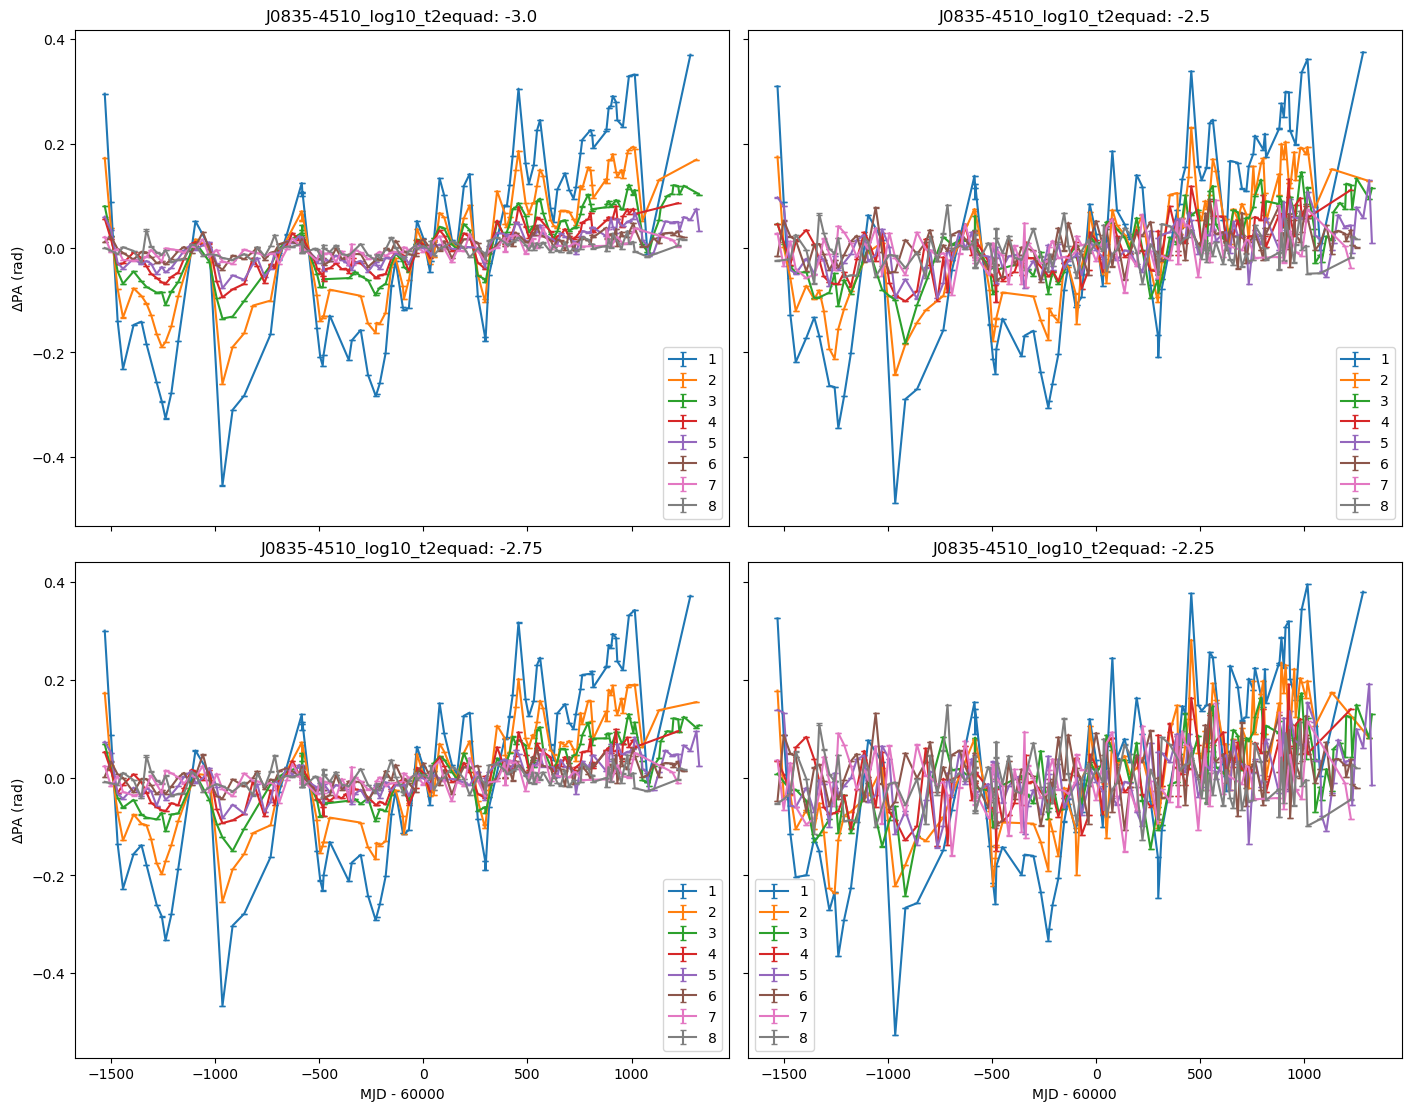

In [21]:
sampler = m_RM.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # fix parameters to reasonable value
        params = {
            'J0835-4510_efac':10.000,
            'J0835-4510_log10_ecorr':-5.000,
            'J0835-4510_log10_t2equad':-3.000+(i+2*j)/4,
            'J0835-4510_rmgp_gamma':0.986,
            'J0835-4510_rmgp_log10_A':-8.121
            }

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42)#+i+2*j)
        key, res = sampler(key, params)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.set_title(f'J0835-4510_log10_t2equad: {params['J0835-4510_log10_t2equad']}')
        ax.legend()

plt.plot()

In [22]:
logL = m_RM.logL

# static layout shared by every Params built inside the model
layout, size = make_layout(logL.params)

# flat uniform bounds, one entry per (scalar) parameter
bounds = [prior.getprior_uniform(p) for p in logL.params]
print(bounds)
lo = jnp.array([b[0] for b in bounds])
hi = jnp.array([b[1] for b in bounds])

def numpyro_model():
    raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
    numpyro.factor('logl', logL(Params(raw, layout)))

[[0.1, 10], [-3, -1], [-3.5, -1.5], [0, 2], [-9, -7]]


In [28]:
jax.devices()

[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]

In [31]:
sampler = infer.MCMC(infer.NUTS(numpyro_model), num_chains=4,
                     num_warmup=200, num_samples=300)
sampler.run(jax.random.PRNGKey(42))

Compiling.. :   0%|          | 0/500 [00:00<?, ?it/s]







In [32]:
raw_samples = sampler.get_samples()['raw']
# print(raw_samples)

p_fit = {}
for i, name in enumerate(logL.params):
    col = raw_samples[:, i]
    print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  bounds={bounds[i]}')
    p_fit[name] = col.mean()

print(p_fit)
print(f'{logL(p_fit):e}')



Running chain 0:  10%|█         | 50/500 [24:24<3:47:06, 30.28s/it]


Running chain 0:  15%|█▌        | 75/500 [34:27<3:14:29, 27.46s/it]





KeyboardInterrupt: 

Running chain 0:  20%|██        | 100/500 [49:23<3:25:09, 30.77s/it]




In [ ]:
figure = corner.corner(
    np.array(raw_samples),
    labels=logL.params
    )
print(type(raw_samples))

#### Add achromatic red noise

In [30]:
m_red = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp'),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, name='rednoise')
                         ])
print(m_red.logL.params)

['J0835-4510_efac', 'J0835-4510_log10_ecorr', 'J0835-4510_log10_t2equad', 'J0835-4510_rednoise_gamma', 'J0835-4510_rednoise_log10_A', 'J0835-4510_rmgp_gamma', 'J0835-4510_rmgp_log10_A']


In [31]:
from discovery import prior
from discovery.params import Params, make_layout

import numpyro
from numpyro import infer, distributions as dist

In [ ]:
logL = m_red.logL

# static layout shared by every Params built inside the model
layout, size = make_layout(logL.params)

# flat uniform bounds, one entry per (scalar) parameter
bounds = [prior.getprior_uniform(p) for p in logL.params]
print(bounds)
lo = jnp.array([b[0] for b in bounds])
hi = jnp.array([b[1] for b in bounds])

def numpyro_model():
    raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
    numpyro.factor('logl', logL(Params(raw, layout)))

[[0.1, 10], [-3, -1], [-3.5, -1.5], [0, 7], [-10, -8], [0, 2], [-9, -7]]


[]

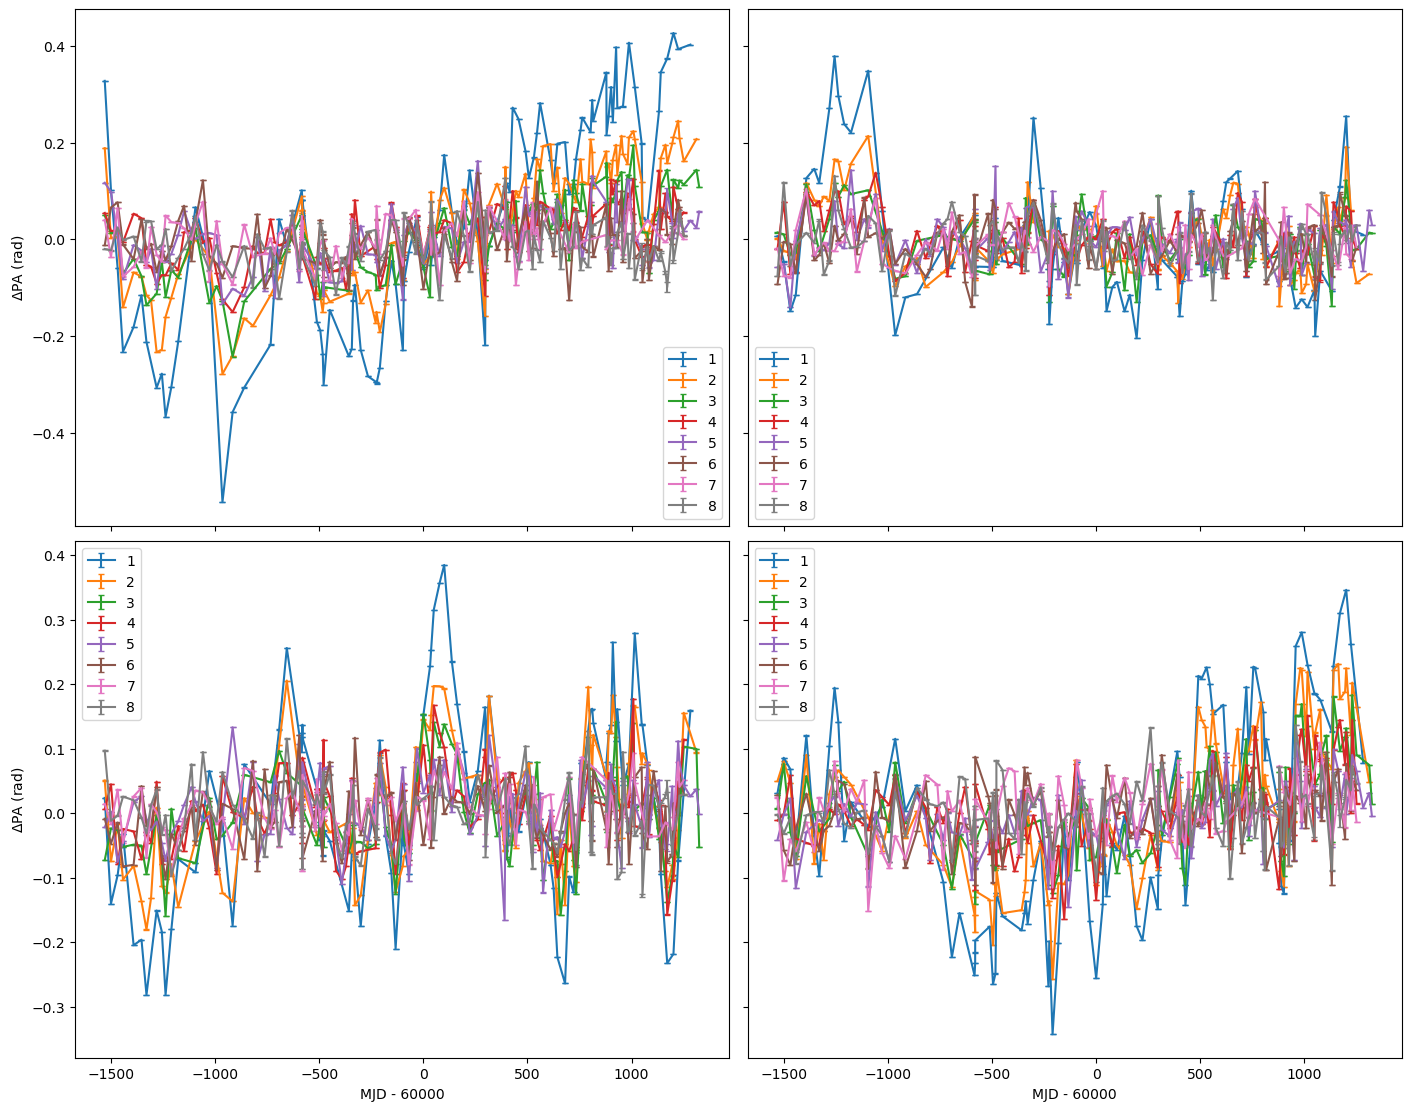

In [ ]:
sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # fix parameters to reasonable value
        # params = {
        #     'J0835-4510_efac':4.0,#7.405,
        #     'J0835-4510_log10_ecorr':-2.006,
        #     'J0835-4510_log10_t2equad':-2.287,
        #     'J0835-4510_rednoise_gamma':2.0, 
        #     'J0835-4510_rednoise_log10_A':-9,
        #     'J0835-4510_rmgp_gamma':1.118,
        #     'J0835-4510_rmgp_log10_A':-8.140
        #     }
        params = {
        'J0835-4510_efac':6.635,
        'J0835-4510_log10_ecorr':-1.603,
        'J0835-4510_log10_t2equad':-2.252,
        'J0835-4510_rednoise_gamma':1.403,
        'J0835-4510_rednoise_log10_A':-9.615,
        'J0835-4510_rmgp_gamma':1.192,
        'J0835-4510_rmgp_log10_A':-8.135
        }

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = sampler(key, params)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

In [74]:
sampler = infer.MCMC(infer.NUTS(numpyro_model),
                     num_warmup=200, num_samples=300)
sampler.run(jax.random.PRNGKey(42))

sample: 100%|██████████| 500/500 [2:57:47<00:00, 21.34s/it, 127 steps of size 4.47e-02. acc. prob=0.88]  


In [75]:
raw_samples = sampler.get_samples()['raw']
# print(raw_samples)

p_fit = {}
for i, name in enumerate(logL.params):
    col = raw_samples[:, i]
    print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  bounds={bounds[i]}')
    p_fit[name] = col.mean()

print(p_fit)
print(f'{logL(p_fit):e}')

J0835-4510_efac                mean=+6.635  std=2.413  bounds=[0.1, 10]
J0835-4510_log10_ecorr         mean=-1.603  std=0.033  bounds=[-3, -1]
J0835-4510_log10_t2equad       mean=-2.252  std=0.204  bounds=[-3.5, -1.5]
J0835-4510_rednoise_gamma      mean=+1.403  std=0.979  bounds=[0, 4]
J0835-4510_rednoise_log10_A    mean=-9.615  std=0.274  bounds=[-10, -8]
J0835-4510_rmgp_gamma          mean=+1.192  std=0.244  bounds=[0, 2]
J0835-4510_rmgp_log10_A        mean=-8.135  std=0.046  bounds=[-9, -7]
{'J0835-4510_efac': Array(6.63513221, dtype=float64), 'J0835-4510_log10_ecorr': Array(-1.60322567, dtype=float64), 'J0835-4510_log10_t2equad': Array(-2.25244248, dtype=float64), 'J0835-4510_rednoise_gamma': Array(1.40349858, dtype=float64), 'J0835-4510_rednoise_log10_A': Array(-9.61481815, dtype=float64), 'J0835-4510_rmgp_gamma': Array(1.19228014, dtype=float64), 'J0835-4510_rmgp_log10_A': Array(-8.13492785, dtype=float64)}
2.618152e+03


<class 'jaxlib._jax.ArrayImpl'>


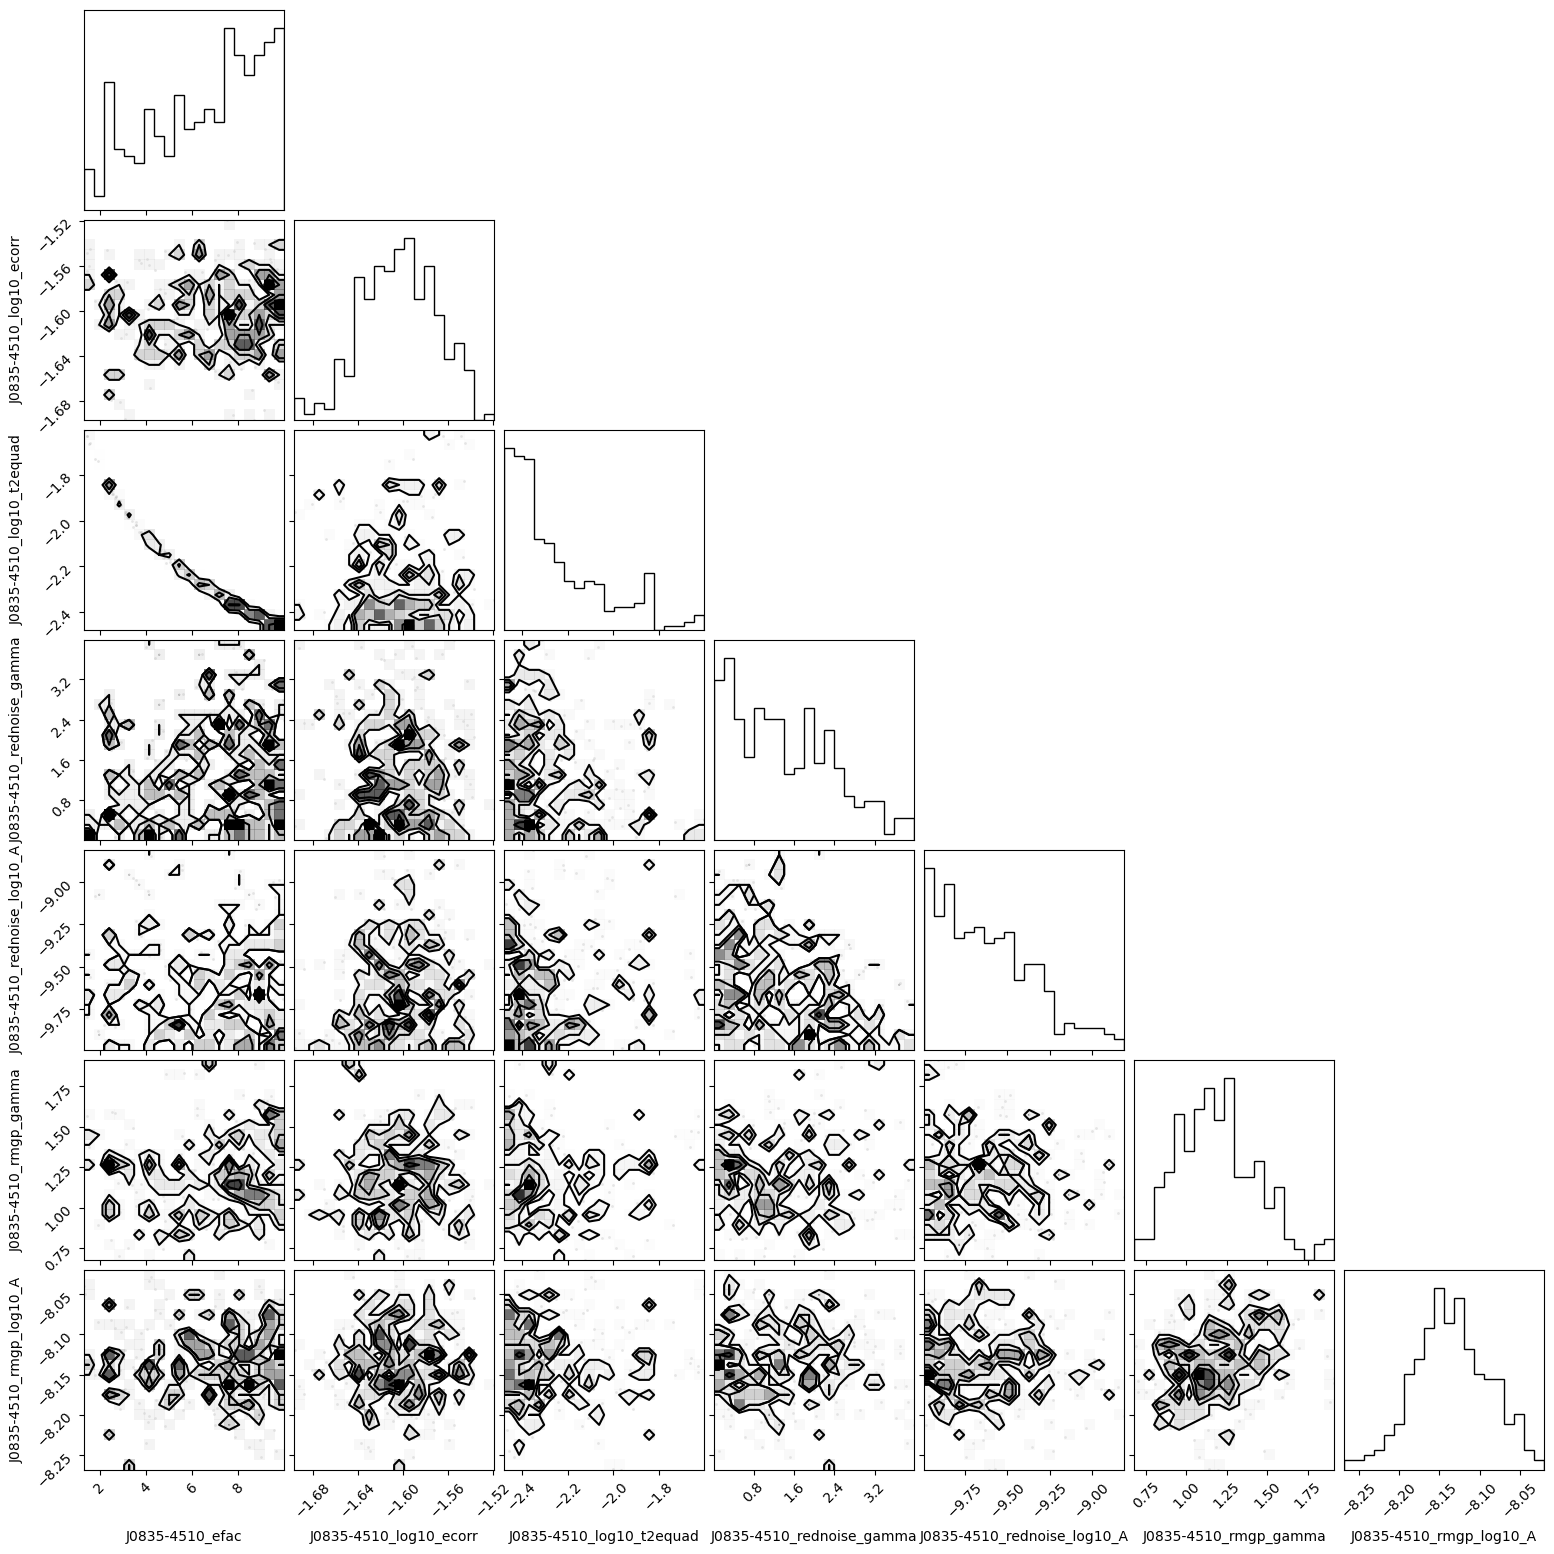

In [ ]:
figure = corner.corner(
    np.array(raw_samples),
    labels=logL.params
    )
print(type(raw_samples))

In [1]:
# sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_red.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

NameError: name 'plt' is not defined

#### Time-domain RM noise

In [ ]:
# n_obs = ds.quantize(psr.toas, dt=1.0)[-1]; print(n_obs)

# m_RM_t = ds.PulsarLikelihood([psr.residuals,
#                          ds.makenoise_measurement_simple(psr),
#                          ds.makegp_ecorr_simple(psr),
#                          ds.makegp_fftcov_dm(psr, ds.powerlaw, components=23, oversample=6, name='dmgp') # Label RM as DM to get prior
#                          ])
# print(m_RM_t.logL.params)

In [ ]:
# p0 = ds.sample_uniform(m_RM.logL.params)
# print(p0)
# print(f'Noise:            {m.logL(p0):e}')
# print(f'Noise+ECORR:      {m_ecorr.logL(p0):e}')
# print(f'Noise+ECORR+RM:   {m_RM.logL(p0):e}')
# print(f'Noise+ECORR+RM_t: {m_RM.logL(p0):e}')

In [ ]:
# logL_RM_t = m_RM_t.logL

# # static layout shared by every Params built inside the model
# layout, size = make_layout(logL_RM_t.params)

# # flat uniform bounds, one entry per (scalar) parameter
# bounds = [prior.getprior_uniform(p) for p in logL_RM_t.params]
# lo = jnp.array([b[0] for b in bounds])
# hi = jnp.array([b[1] for b in bounds])

# def numpyro_model_RM_t():
#     raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
#     numpyro.factor('logl', logL_RM_t(Params(raw, layout)))

In [ ]:
# sampler_RM_t = infer.MCMC(infer.NUTS(numpyro_model_RM_t),
#                      num_warmup=200, num_samples=200)
# sampler_RM_t.run(jax.random.PRNGKey(42))

In [ ]:
# raw_samples = sampler.get_samples()['raw']
# # print(raw_samples)

# p_fit = {}
# for i, name in enumerate(logL.params):
#     col = raw_samples[:, i]
#     print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}')
#     p_fit[name] = col.mean()

# print(p_fit)
# print(f'{logL(p_fit):e}')